## Análise de Capacidade e Distribuição da Procura (Dataset Small)
**Autor:** Fábio Ferreira (29365)

### 1. Carregamento e Preparação dos Dados
Carregamos os ficheiros CSV necessários para analisar a relação entre o peso das encomendas e a capacidade da frota (`order_items`, `orders`, `products`, `producers`, `delivery_locations` e `vehicles`). Cruzamos os itens com os respetivos produtos e encomendas e extraímos o dia e a hora das janelas temporais para avaliar a evolução da procura ao longo do tempo.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Altera para "docs/data_tiny/" se quiseres correr para o tiny
DATA = "docs/data_tiny/"
DATE_COLS = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

# 1. Carregar apenas os CSVs necessários para Capacidade e Procura
items      = pd.read_csv(DATA + "order_items.csv", parse_dates=DATE_COLS)
orders     = pd.read_csv(DATA + "orders.csv", parse_dates=["order_datetime"])
products   = pd.read_csv(DATA + "products.csv")
producers  = pd.read_csv(DATA + "producers.csv")
deliv_locs = pd.read_csv(DATA + "delivery_locations.csv")
vehicles   = pd.read_csv(DATA + "vehicles.csv")

# 2. Cruzar tabelas (Merge)
df = items.merge(products[["product_id", "producer_id", "name", "category", "unit", "unit_weight_kg"]], on="product_id", how="left")
df = df.merge(orders[["order_id", "customer_id", "delivery_location_id", "status"]], on="order_id", how="left")

# Garantir que weight_kg existe (necessário caso corras no dataset tiny)
if "weight_kg" not in df.columns:
    df["weight_kg"] = df["quantity"] * df["unit_weight_kg"]

# 3. Extrair variáveis temporais (Dia e Hora)
df["dia_recolha"]  = df["availability_start"].dt.date
df["dia_entrega"]  = df["delivery_start"].dt.date
df["hora_recolha"] = df["availability_start"].dt.hour
df["hora_entrega"] = df["delivery_start"].dt.hour

display(df.head())

,order_item_id,order_id,product_id,quantity,weight_kg,availability_start,availability_end,delivery_start,delivery_end,producer_id,...,category,unit,unit_weight_kg,customer_id,delivery_location_id,status,dia_recolha,dia_entrega,hora_recolha,hora_entrega
0,1,1,10,6.3,6.3,2026-10-31 07:30:00,2026-10-31 10:30:00,2026-10-31 10:30:00,2026-10-31 12:45:00,2,...,vegetable,kg,1.0,9,3,confirmed,2026-10-31,2026-10-31,7,10
1,2,1,3,3.7,3.7,2026-10-31 08:15:00,2026-10-31 11:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00,1,...,fruit,kg,1.0,9,3,confirmed,2026-10-31,2026-10-31,8,10
2,3,1,15,4.9,4.9,2026-10-31 07:30:00,2026-10-31 10:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00,3,...,vegetable,kg,1.0,9,3,confirmed,2026-10-31,2026-10-31,7,10
3,4,1,13,7.1,7.1,2026-10-31 07:15:00,2026-10-31 10:45:00,2026-10-31 10:30:00,2026-10-31 12:45:00,3,...,fruit,kg,1.0,9,3,confirmed,2026-10-31,2026-10-31,7,10
4,5,2,3,1.8,1.8,2026-10-30 07:15:00,2026-10-30 11:15:00,2026-10-31 07:15:00,2026-10-31 10:15:00,1,...,fruit,kg,1.0,3,4,confirmed,2026-10-30,2026-10-31,7,7


### 2. Peso a Transportar vs. Capacidade dos Veículos
Comparamos a procura total e diária com a capacidade máxima da frota. Como as regras operacionais do conjunto *small* exigem que todos os produtos passem pelo centro de recolha (`producer > warehouse > delivery_location`), o esforço de transporte divide-se em duas operações distintas: recolhas nos produtores e entregas nos clientes.

Peso Total (2 dias): 270.0 kg | Capacidade Total da Frota: 350.0 kg


,vehicle_id,capacity_kg,refrigerated
0,1,150.0,1
1,2,200.0,0


,itens_recolha,peso_recolha_kg,itens_entrega,peso_entrega_kg,% frota (recolha),% frota (entrega)
dia_recolha,,,,,,
2026-10-30,24,166.9,14,104.6,47.7,29.9
2026-10-31,16,103.1,26,165.4,29.5,47.3


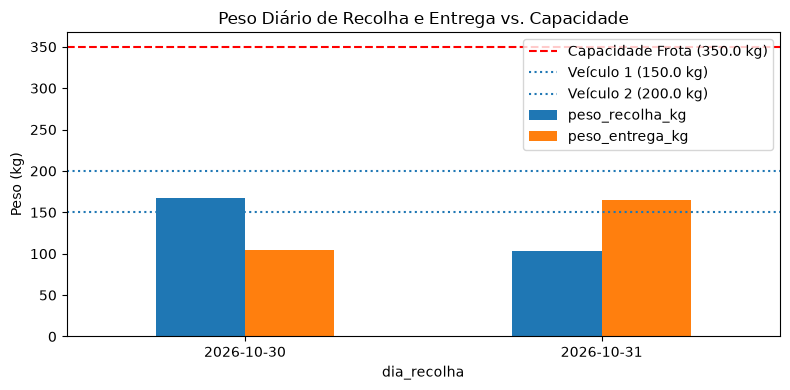

In [3]:
cap_total = vehicles["capacity_kg"].sum()
peso_total = df["weight_kg"].sum()

print(f"Peso Total (2 dias): {peso_total:.1f} kg | Capacidade Total da Frota: {cap_total:.1f} kg")
display(vehicles[["vehicle_id", "capacity_kg", "refrigerated"]])

# Agrupar por dia de Recolha e por dia de Entrega
recolha_dia = df.groupby("dia_recolha").agg(itens_recolha=("order_item_id", "count"), peso_recolha_kg=("weight_kg", "sum"))
entrega_dia = df.groupby("dia_entrega").agg(itens_entrega=("order_item_id", "count"), peso_entrega_kg=("weight_kg", "sum"))

resumo_dias = recolha_dia.join(entrega_dia)

# Calcular % de ocupação da frota total por dia
resumo_dias["% frota (recolha)"] = (100 * resumo_dias["peso_recolha_kg"] / cap_total).round(1)
resumo_dias["% frota (entrega)"] = (100 * resumo_dias["peso_entrega_kg"] / cap_total).round(1)
display(resumo_dias)

# Gráfico comparativo
ax = resumo_dias[["peso_recolha_kg", "peso_entrega_kg"]].plot.bar(figsize=(8, 4), rot=0)
ax.axhline(cap_total, color="red", linestyle="--", label=f"Capacidade Frota ({cap_total} kg)")
for vid, cap in vehicles[["vehicle_id", "capacity_kg"]].itertuples(index=False):
    ax.axhline(cap, linestyle=":", label=f"Veículo {vid} ({cap} kg)")
ax.set_ylabel("Peso (kg)")
ax.set_title("Peso Diário de Recolha e Entrega vs. Capacidade")
ax.legend()
plt.tight_layout()
plt.show()